BENIGN VS MALIGNANT COMPARISON
Benign images: 547
Malignant images: 470
PIXEL STATISTICS BY CLASS:
Benign:
   Mean intensity: -0.261
   Std deviation: 0.932
Malignant:
   Mean intensity: -0.255
   Std deviation: 0.941
Difference in means: 0.006


C:\Users\Test\AppData\Local\Temp\ipykernel_22176\4001389689.py:55: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([benign_pixels[::1000], malignant_pixels[::1000]],


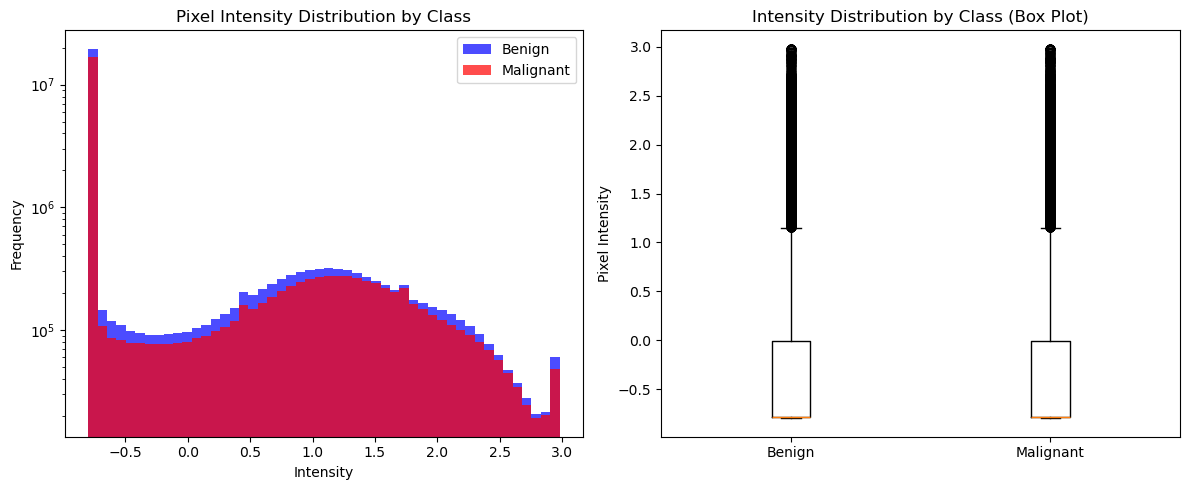

PER-IMAGE STATISTICS BY CLASS:
Benign:
   Mean over images: -0.261
   Std over images:  0.176
Malignant:
   Mean over images: -0.255
   Std over images:  0.171

INTERPRETATION:
--------------------------------------------------
The difference in means is 0.006.
Look for visual differences in the distributions above.


In [1]:
# Notebook 5: Class Comparison
import os
import numpy as np
import matplotlib.pyplot as plt

# Path to data
SAVE_DIR = "../processed_data/"

# Load data
X_train = np.load(os.path.join(SAVE_DIR, 'X_train.npy'))
y_train = np.load(os.path.join(SAVE_DIR, 'y_train.npy'))

print("="*70)
print("BENIGN VS MALIGNANT COMPARISON")
print("="*70)

# Separate by class
benign_images = X_train[y_train == 0]
malignant_images = X_train[y_train == 1]

print(f"Benign images: {benign_images.shape[0]}")
print(f"Malignant images: {malignant_images.shape[0]}")

# Statistics by class
print("PIXEL STATISTICS BY CLASS:")

benign_mean = benign_images.mean()
benign_std = benign_images.std()
malignant_mean = malignant_images.mean()
malignant_std = malignant_images.std()

print(f"Benign:")
print(f"   Mean intensity: {benign_mean:.3f}")
print(f"   Std deviation: {benign_std:.3f}")
print(f"Malignant:")
print(f"   Mean intensity: {malignant_mean:.3f}")
print(f"   Std deviation: {malignant_std:.3f}")
print(f"Difference in means: {abs(benign_mean - malignant_mean):.3f}")

# Visualize intensity distributions by class
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

benign_pixels = benign_images.flatten()
malignant_pixels = malignant_images.flatten()

axes[0].hist(benign_pixels, bins=50, alpha=0.7, color='blue', label='Benign')
axes[0].hist(malignant_pixels, bins=50, alpha=0.7, color='red', label='Malignant')
axes[0].set_title('Pixel Intensity Distribution by Class')
axes[0].set_xlabel('Intensity')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].set_yscale('log')

# Box plot (sample for speed)
axes[1].boxplot([benign_pixels[::1000], malignant_pixels[::1000]], 
                labels=['Benign', 'Malignant'])
axes[1].set_title('Intensity Distribution by Class (Box Plot)')
axes[1].set_ylabel('Pixel Intensity')

plt.tight_layout()
plt.savefig('intensity_by_class.png', dpi=150)
plt.show()

# Per-image statistics
print("PER-IMAGE STATISTICS BY CLASS:")

benign_per_image_mean = benign_images.mean(axis=(1, 2))
malignant_per_image_mean = malignant_images.mean(axis=(1, 2))
benign_per_image_std = benign_images.std(axis=(1, 2))
malignant_per_image_std = malignant_images.std(axis=(1, 2))

print(f"Benign:")
print(f"   Mean over images: {benign_per_image_mean.mean():.3f}")
print(f"   Std over images:  {benign_per_image_mean.std():.3f}")
print(f"Malignant:")
print(f"   Mean over images: {malignant_per_image_mean.mean():.3f}")
print(f"   Std over images:  {malignant_per_image_mean.std():.3f}")

print("\nINTERPRETATION:")
print("-"*50)
print(f"The difference in means is {abs(benign_mean - malignant_mean):.3f}.")
print("Look for visual differences in the distributions above.")